## Step 1: Installing Requirements

In [6]:
%pip install opencv-python mediapipe pygame pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
%pip install mediapipe pygame

import sys
print(sys.executable)   
print(sys.version)      

import cv2, mediapipe, pygame, pandas
print("opencv   ", cv2.__version__)
print("mediapipe", mediapipe.__version__)
print("pygame   ", pygame.version.ver)
print("pandas   ", pandas.__version__)
print("All four imports working")


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
c:\Users\Prachi\AppData\Local\Programs\Python\Python311\python.exe
3.11.7 (tags/v3.11.7:fa7a6f2, Dec  4 2023, 19:24:49) [MSC v.1937 64 bit (AMD64)]
pygame 2.6.1 (SDL 2.28.4, Python 3.11.7)
Hello from the pygame community. https://www.pygame.org/contribute.html
opencv    4.11.0
mediapipe 0.10.21
pygame    2.6.1
pandas    2.3.3
All four imports working


In [8]:
import time
import cv2
import mediapipe as mp
import pandas as pd
from IPython.display import display, Image

DURATION = 20   

def to_jpeg(frame):
    return Image(data=cv2.imencode(".jpg", frame)[1].tobytes())

def open_cam(index=0):
    cap = cv2.VideoCapture(index)
    if not cap.isOpened():
        raise RuntimeError("Cannot open webcam (try index 1 or check camera permissions)")
    return cap

## Step 2: Webcam with FPS

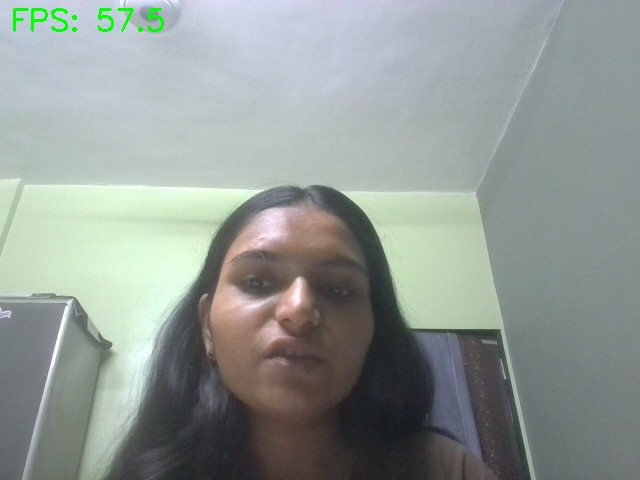

In [9]:
cap = open_cam()
handle = display(None, display_id=True)
prev, fps, start = time.time(), 0.0, time.time()
try:
    while time.time() - start < DURATION:
        ok, frame = cap.read()
        if not ok:
            break
        now = time.time()
        fps = 0.9 * fps + 0.1 * (1 / max(now - prev, 1e-6))
        prev = now
        cv2.putText(frame, f"FPS: {fps:.1f}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
        handle.update(to_jpeg(frame))
except KeyboardInterrupt:
    pass
finally:
    cap.release()   

## Step 3: Pose skeleton 

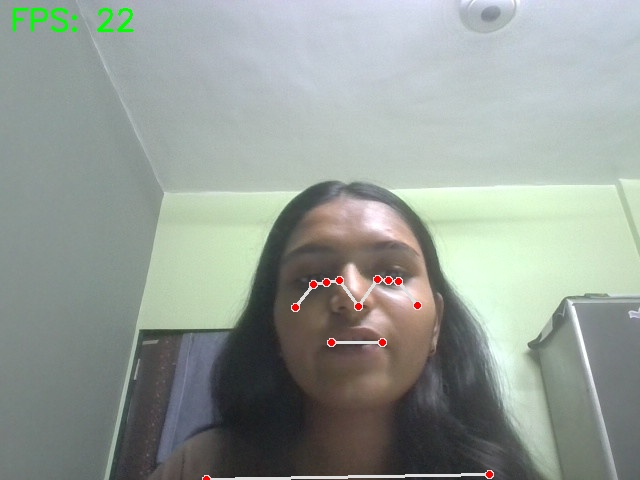

In [10]:
mp_pose = mp.solutions.pose
mp_draw = mp.solutions.drawing_utils

cap = open_cam()
handle = display(None, display_id=True)
prev, start = time.time(), time.time()
try:
    with mp_pose.Pose(min_detection_confidence=0.5, min_tracking_confidence=0.5) as pose:
        while time.time() - start < DURATION:
            ok, frame = cap.read()
            if not ok:
                break
            frame = cv2.flip(frame, 1)
            res = pose.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            if res.pose_landmarks:
                mp_draw.draw_landmarks(frame, res.pose_landmarks, mp_pose.POSE_CONNECTIONS)
            now = time.time()
            cv2.putText(frame, f"FPS: {1 / max(now - prev, 1e-6):.0f}", (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
            prev = now
            handle.update(to_jpeg(frame))
except KeyboardInterrupt:
    pass
finally:
    cap.release()

## Step 4: Print x, y of nose, wrists, knees every frame 

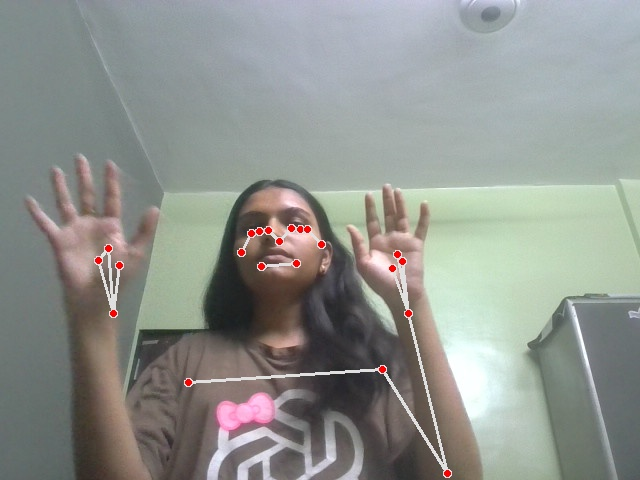

[0] nose=(347,141)  l_wrist=(562,653)  r_wrist=(142,654)  l_knee=(428,967)  r_knee=(262,964)
[1] nose=(358,141)  l_wrist=(565,628)  r_wrist=(165,640)  l_knee=(448,972)  r_knee=(283,967)
[2] nose=(363,141)  l_wrist=(571,608)  r_wrist=(180,638)  l_knee=(467,973)  r_knee=(305,968)
[3] nose=(369,143)  l_wrist=(571,585)  r_wrist=(188,625)  l_knee=(477,973)  r_knee=(317,967)
[4] nose=(371,144)  l_wrist=(590,587)  r_wrist=(182,641)  l_knee=(479,973)  r_knee=(318,966)
[5] nose=(373,147)  l_wrist=(592,597)  r_wrist=(191,640)  l_knee=(483,972)  r_knee=(319,966)
[6] nose=(375,150)  l_wrist=(573,566)  r_wrist=(241,501)  l_knee=(480,973)  r_knee=(314,966)
[7] nose=(378,150)  l_wrist=(571,580)  r_wrist=(230,556)  l_knee=(478,973)  r_knee=(311,967)
[8] nose=(373,150)  l_wrist=(537,575)  r_wrist=(240,489)  l_knee=(476,970)  r_knee=(308,962)
[9] nose=(365,150)  l_wrist=(526,589)  r_wrist=(232,530)  l_knee=(460,967)  r_knee=(290,956)
[10] nose=(356,150)  l_wrist=(519,524)  r_wrist=(239,494)  l_knee=(458

,frame,nose_x,nose_y,l_wrist_x,l_wrist_y,r_wrist_x,r_wrist_y,l_knee_x,l_knee_y,r_knee_x,r_knee_y
0,0,347,141,562,653,142,654,428,967,262,964
1,1,358,141,565,628,165,640,448,972,283,967
2,2,363,141,571,608,180,638,467,973,305,968
3,3,369,143,571,585,188,625,477,973,317,967
4,4,371,144,590,587,182,641,479,973,318,966


In [12]:
P = mp_pose.PoseLandmark
TRACKED = {"nose": P.NOSE,
           "l_wrist": P.LEFT_WRIST, "r_wrist": P.RIGHT_WRIST,
           "l_knee": P.LEFT_KNEE,   "r_knee": P.RIGHT_KNEE}

cap = open_cam()
handle = display(None, display_id=True)
rows, frame_no, start = [], 0, time.time()
try:
    with mp_pose.Pose() as pose:
        while time.time() - start < DURATION:
            ok, frame = cap.read()
            if not ok:
                break
            frame = cv2.flip(frame, 1)
            h, w = frame.shape[:2]
            res = pose.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            if res.pose_landmarks:
                mp_draw.draw_landmarks(frame, res.pose_landmarks, mp_pose.POSE_CONNECTIONS)
                lm = res.pose_landmarks.landmark
                row, parts = {"frame": frame_no}, []
                for name, idx in TRACKED.items():
                    x, y = lm[idx].x * w, lm[idx].y * h
                    row[f"{name}_x"], row[f"{name}_y"] = round(x), round(y)
                    parts.append(f"{name}=({x:.0f},{y:.0f})")
                print(f"[{frame_no}] " + "  ".join(parts))
                rows.append(row)
            else:
                print(f"[{frame_no}] no person detected")
            frame_no += 1
            handle.update(to_jpeg(frame))
except KeyboardInterrupt:
    pass
finally:
    cap.release()

df = pd.DataFrame(rows)
df.to_csv("pose_log.csv", index=False)
print(f"Saved {len(df)} frames to pose_log.csv")
df.head()